<a href="https://colab.research.google.com/github/hyo-yeon-lee/MCNB-Introduction-to-Programming/blob/main/3_functions_dicts_shuffling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Functions, dictionaries, and shuffling

This week we are covering several crucial general coding topics. Remember you have access to datacamp if you want more exercises to practice.

#Practical 1: using functions to interact with fMRI data
###Topics: functions.

We will use the same real fMRI dataset as last week. Please download it from Learn@FU. If you don't have access to Learn@FU, please ask your neighbour to send it to you via email.

The dataset contains the voxel responses for 159 stimuli. It is a numpy array.

**You need to download the `fmri_data.npy` file from Learn@FU, and upload it here. Click on the file icon in the vertical bar on the left of the screen, and drag+drop the file in there.**

Here is how you can load the fmri data from the `fmri_data.npy` file:

In [3]:
import numpy as np
fmri_data = np.load('/fmri_data.npy')

Make a function that returns the mean and standard deviation of an array over rows specified by an indexing array.

For example, ```mu_sigma_by_indices(input_array, [0,33,58,104])``` returns the means of the input_array over rows [0,33,58,104].

Questions:
1. What is the mean and std of our fmri data over rows [0,33,58,104]?
2. What about the mean over even-numbered rows? (For this you will need to make an indexing array with all even numbers smaller than the number of rows in the fmri data. You can use np.arange() for this. Look online for ideas if you cant figure it out.)

In [4]:
# Replace the following line by your code
def mu_sigma_by_indices(input_array):
  mu = np.mean(input_array)
  sigma = np.std(input_array)

  return mu, sigma

#Practical 2: Applying functions, indexing, broadcasting, basic plotting

In this exercise, we will simulate a simple EEG dataset. The dataset contains EEG recordings for 1000 trials, 1 electrode, and 512 timepoints. Each trial can be either in condition 1 or condition 2 (e.g. 0 could mean a trial with a left-oriented gabor, and 1 a trial with a right-oriented gabor).

I give you:

- A ```conditions``` vector telling us, for each trial, of it was condition 0 or 1.
- An ```EEG_data``` array containing the 512 timepoints for our EEG electrode, for each trial.

>Note: The following cell generates a fake, simulated EEG dataset for us to work with. **You do not need to understand it** (but feel free to look at it if you want of course).



In [6]:
import numpy as np

# for reproducibility
np.random.seed(42)

# Setup parameters
n_stims = 1000  # Number of stimuli
n_electrodes = 128  # Number of electrodes
n_timepoints = 512  # Number of timepoints

# Simulate conditions (0 for correct, 1 for incorrect)
conditions = np.random.choice([0, 1], size=n_stims)

# Create EEG data that resembles evoked potentials
def generate_eeg_condition(condition):
    time = np.linspace(0, 1, n_timepoints)
    if condition == 0:  # Condition 0: correct trials
        # Create a waveform with a positive peak followed by a negative peak
        eeg_waveform = 1+ 2 * np.sin(2 * np.pi * 5 * time) * np.exp(-50 * (time - 0.3)**2)  # Gaussian shape centered around 0.3s
    else:  # Condition 1: incorrect trials
        # Different waveform for incorrect trials
        eeg_waveform = 1 + 1.5 * np.sin(2 * np.pi * 5 * time) * np.exp(-50 * (time - 0.4)**2)  # Gaussian shape centered around 0.4s

    # Create a random noise component to make it more realistic
    noise = np.random.normal(0, 0.2, n_timepoints)
    return eeg_waveform + noise

# Generate EEG data for each stimulus based on its condition
EEG_data = np.array([generate_eeg_condition(cond) for cond in conditions])

As usual, it is good practice to print the shape of stuff to understand what is what. Please do this now for the ```conditions``` and ```EEG_data``` np arrays. Make sure you know what the rows and cols are, and how to find the EEG timecourse for a given stimulus.

In [23]:
# Replace the following line by your code
print("conditions: ", np.shape(conditions))
print("EEG data: ", np.shape(EEG_data))

conditions:  (1000,)
EEG data:  (1000, 512)


Make a function ```get_EEG_stats(EEG_data, conds, stats_across)``` that takes the eeg dataset, an indexing array of conditions, and either ```'stimuli'```, ```'timepoints'```, or ```'global'``` as arguments.

It should return the mean and std of the EEG_data for the conditions specified by the ```conds``` argument of the function. if ```stats_across='stimuli'```, it should return the statistics computed across stimuli, if ```stats_across='timepoints'```, it should return the statistics computed across timepoints, if ```stats_across='global'```, it should return statistics across both (e.g., global average of the whole data).

**I repeat: these statistics should be computed only for the stimuli specified by the ```conds``` argument!**

Fill in the missing parts of the code below.

In [80]:
# Function to calculate EEG statistics
def get_EEG_stats(EEG_data, conds, stats_across):
    # Select the EEG data for the conditions specified by conds
    EEG_data_conds = EEG_data[conds]

    # If/elif/else statement to average across the right dimension specified by stats_across
    if stats_across == 'stimuli':
        # Stats across timepoints
        mean = np.mean(EEG_data_conds, axis=0)
        std = np.std(EEG_data_conds, axis=0)
    elif stats_across == 'timepoints':
        # Stats across timepoints
        mean = np.mean(EEG_data_conds, axis=1)
        std = np.std(EEG_data_conds, axis=1)
    elif stats_across == 'global':
        # Stats globally across everything
        mean = np.mean(EEG_data_conds)
        std = np.std(EEG_data_conds)
    else:
        raise ValueError("Invalid stats_across value. Use 'timepoints', 'electrodes', or 'global'.")

    return mean, std



Now, use your function to retrieve the global mean and std across the whole data, both for cond1 and cond2.

Then plot it as a box plot, as we did previously in practical 1.

To do so, fill in the missing code below.

>Hint: it should look like two bars of similar height, with large error bars.

1.0003720016967408 0.627628847657637


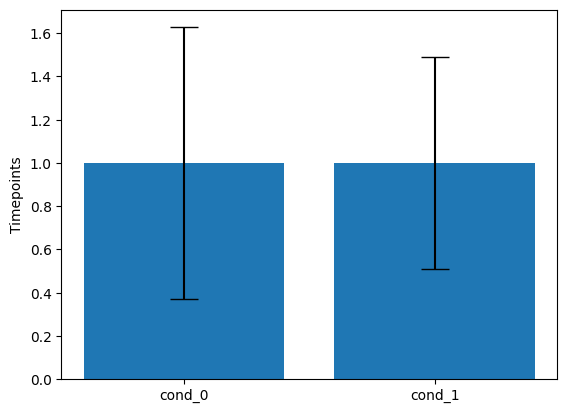

In [92]:
import matplotlib.pyplot as plt

# Get cond0 and cond1 indexing arrays
# indexing_arrays = conditions == 0
cond0_indices = conditions==0
cond1_indices = conditions==1

# Get EEG statistics for correct and incorrect trials
cond0_mean, cond0_std = get_EEG_stats(EEG_data, cond0_indices, 'global')
cond1_mean, cond1_std = get_EEG_stats(EEG_data, cond1_indices, 'global')
print(cond0_mean, cond0_std)
# cond1_mean, cond1_std = # TODO

# # Plot the global mean and std for correct vs. incorrect trials
# # Replace this with your bar plot code
plt.bar([0, 1], [cond0_mean, cond1_mean], yerr=[cond0_std, cond1_std], capsize=10)
plt.xticks([0, 1], ["cond_0", "cond_1"])
plt.ylabel("Timepoints")
plt.show()

Now, use your function to get the means for cond0 and cond1, averaged across **stimuli**. Check that the shapes make sense. *Really think about why we end up with 512 values!*

Then, the code already written will plot the timecourse for both conditions. *Look at the plotting code to familiarise yourself with how it works: we will go more in depth next week*.

>Hint: you should see a blue and an orange timecourse, they should look different.

stim_averaged_EEG_data shape for cond0:  (512,)
stim_averaged_EEG_data shape for cond1:  (512,)


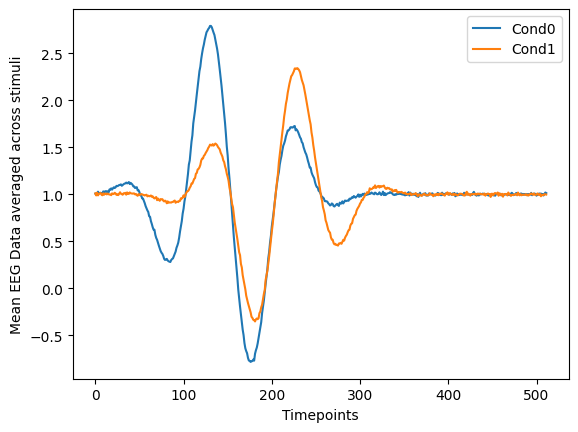

In [91]:
mean_cond0_stim, std_cond0_stim = get_EEG_stats(EEG_data, cond0_indices, 'stimuli')
print('stim_averaged_EEG_data shape for cond0: ', mean_cond0_stim.shape)  # Should print (512,)

mean_cond1_stim, std_cond1_stim = get_EEG_stats(EEG_data, cond1_indices, 'stimuli')
print('stim_averaged_EEG_data shape for cond1: ', mean_cond1_stim.shape)  # Should print (512,)

import matplotlib.pyplot as plt
time_points = np.arange(mean_cond0_stim.shape[0])
plt.plot(time_points, mean_cond0_stim)
plt.plot(time_points, mean_cond1_stim)
plt.xlabel('Timepoints')
plt.ylabel('Mean EEG Data averaged across stimuli')
plt.legend(['Cond0', 'Cond1'])
plt.show()

Now, use your function to get the means for cond0 and cond1, averaged across **timepoints**. Check that the shapes make sense. *Really think about why we end up with different values for cond0 and cond1! What do the numbers represent?*

Then, the code already written will plot a histogram of values for both conditions. *Look at the plotting code to familiarise yourself with how it works: we will go more in depth next week*.

>Hint: you should see a blue and an orange histogram, largely overlapping, with blue sliightly to to the right of orange.

time_averaged_EEG_data shape for cond0:  (490,)
time_averaged_EEG_data shape for cond1:  (510,)


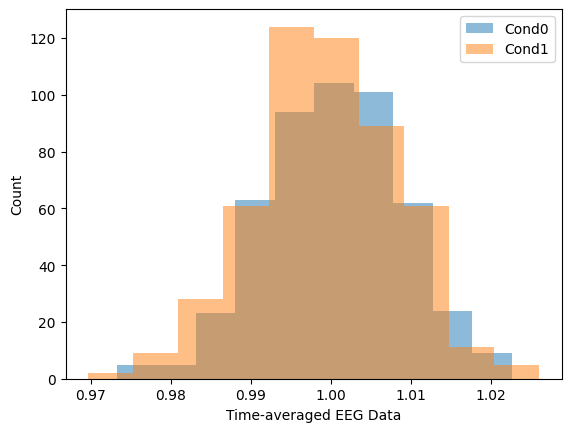

In [93]:
mean_cond0_time, std_cond0_time = get_EEG_stats(EEG_data, cond0_indices, 'timepoints')
print('time_averaged_EEG_data shape for cond0: ', mean_cond0_time.shape)

mean_cond1_time, std_cond1_time = get_EEG_stats(EEG_data, cond1_indices, 'timepoints')
print('time_averaged_EEG_data shape for cond1: ', mean_cond1_time.shape)

plt.hist(mean_cond0_time, alpha=0.5)
plt.hist(mean_cond1_time, alpha=0.5)
plt.xlabel('Time-averaged EEG Data')
plt.ylabel('Count')
plt.legend(['Cond0', 'Cond1'])
plt.show()

#Practical 3: introduction to dicts
We will cover basic operations with python dictionaries.

You can create a dictionary using curly braces ```{}```, with each key-value pair separated by a colon ```:```. Here's an example where we store reaction times (RTs) for different subjects in a cognitive neuroscience experiment:

In [94]:
# Dictionary of reaction times (RTs) for different subjects
rt_data = {
    "subject_1": 450,  # subject 1's RT
    "subject_2": 512,  # subject 2's RT
    "subject_3": 398   # subject 3's RT
}

You can retrieve the value associated with a key using square brackets ```[]```. If the key doesn't exist, Python will throw a ```KeyError```.

In [95]:
# Access RT for subject 2
rt_subject_2 = rt_data["subject_2"]
print(f"Reaction time for subject 2: {rt_subject_2} ms")

Reaction time for subject 2: 512 ms


You can add a new key-value pair like this:

In [96]:
# Adding a new subject's RT
rt_data["subject_4"] = 475

# Print the new value
print(f"Reaction time for subject 4: {rt_data['subject_4']} ms")

Reaction time for subject 4: 475 ms


You can update an existing key-value pair like this:

In [97]:
# Updating RT for subject 1
rt_data["subject_4"] = 460

# Printing the updated dictionary
print(f"Updated reaction time for subject 4: {rt_data['subject_4']} ms")

Updated reaction time for subject 4: 460 ms


You can remove an entry from a dictionary using the ```del``` keyword.

In [98]:
# Deleting subject 3's RT
del rt_data["subject_3"]

You can get all keys, values, or key-value pairs like this.

In [99]:
# Getting all keys
print(rt_data.keys())  # Outputs: dict_keys(['subject_1', 'subject_2', 'subject_4'])

# Getting all values
print(rt_data.values())  # Outputs: dict_values([460, 512, 475])

# Getting all key-value pairs
print(rt_data.items())  # Outputs: dict_items([('subject_1', 460), ('subject_2', 512), ('subject_4', 475)])

dict_keys(['subject_1', 'subject_2', 'subject_4'])
dict_values([450, 512, 460])
dict_items([('subject_1', 450), ('subject_2', 512), ('subject_4', 460)])


This is very useful for looping over dicts. Here is an example:

In [100]:
# Loop through subjects and their RTs
for subject, rt in rt_data.items():
    print(f"{subject}: {rt} ms")

subject_1: 450 ms
subject_2: 512 ms
subject_4: 460 ms


We can easily check if a key exists in the dict, or if a value exists using the following approach:

In [101]:
if "subject_2" in rt_data.keys():
    print("Subject 2's RT is available.")
else:
    print("No data for subject 2.")

if 398 in rt_data.values():
    print("Reaction time 398 exists.")
else:
    print("Reaction time 398 does not exist.")

Subject 2's RT is available.
Reaction time 398 does not exist.


We can also make nested dicts (i.e., dicts inside dicts). This can be useful to log all relevant information for each trial of an experiment for example.

In [102]:
# Dictionary storing reaction times for each subject and each condition
experiment_data = {
    "trial_1": {"RT": 400, "correct": 0},
    "trial_2": {"RT": 420, "correct": 1},
    "trial_3": {"RT": 410, "correct": 1}
}

# Accessing the reaction time for subject 2 in condition B
rt_trial_2 = experiment_data["trial_2"]["RT"]
print(f"RT in trial 2: {rt_trial_2} ms")


RT in trial 2: 420 ms


Note, when making nested dicts inside for loops, you need to make sure that you create the dict keys/values before using them. Here is an example.

In [103]:
example_dict = {}

for a in ['one', 'two', 'three']:
    # create the key for element in a, with an empty value
    # without this line the next for loop would throw a bug,
    # because you would try to assign a value to example_dict[a][b]
    # without having created example_dict[a].
    example_dict[a] = {}

    for b in [1, 2, 3]:
        example_dict[a][b] = b + 10

print(example_dict)

{'one': {1: 11, 2: 12, 3: 13}, 'two': {1: 11, 2: 12, 3: 13}, 'three': {1: 11, 2: 12, 3: 13}}


###Topic: Using dicts to collect experimental data

Let's make a super simple behavioural experiment, and use a dict to collect the data.

In the future, we'll use special software to properly present stimuli and collect timed responses from the participants. For now, we will use the much simpler (but less powerful) ```input()``` function from python. Let's give it a go so you see how it works.

>**Note:** in this example, I am using a *formatted string* in the print statement. Just write f in front of the string and you can print variable if you put them in curly brace {}. Pretty handy trick. Look online if you want more info on this.

In [104]:
a = input("Write a word, then press enter.")
print(f'You wrote {a}')

Write a word, then press enter.blah
You wrote blah


Ok, let's make our experiment now. Here are the step you should code:

1. Declare n_trials = 5
2. Declare empty expt_dict
3. Make a for loop to iterate across trials
4. In the loop:
  - add `f'trial_{trial_number}'` to the dict keys. Make make sure you understand why this is needed. Also notice the formatted string usage here.
  - use `input('your_instruction')` to ask the user to input a number. *NOTE: You need to convert the user input to an int or float, otherwise it will be considered a string! I.e, use something like `float(input('Write a number'))`*
  - Add this to the exp_dict for this trial
  - Do it again, asking for a string, and add it to the exp_dict for this trial. *NOTE: no need to convert to int/float here of course*
5. Print the results for trial 2.
6. Print the average of the input numbers across trials
7. Print a concatenation of all the strings, separated with spaces

Fill in the blanks below.

In [123]:
n_trials = 5

expt_dict = {}
exp_dict = {}

for i in range(n_trials):
  question = float(input("Input a number."))
  expt_dict[i] = question

# print full dict
print("full dict: ", expt_dict)
# print results for the trial 2
print(expt_dict[1])
# print average input number across trials
print(sum(expt_dict.values())/len(expt_dict))

# Print a concatenation of all the strings, separated with spaces
for i in range(n_trials):
  question = input("Input a string.")
  exp_dict[i] = question

words = []
for trial in exp_dict.values():
  words.append(trial)
print(' '.join(words))


Input a number.1
Input a number.2
Input a number.3
Input a number.4
Input a number.5
full dict:  {0: 1.0, 1: 2.0, 2: 3.0, 3: 4.0, 4: 5.0}
2.0
3.0
Input a string.a
Input a string.b
Input a string.c
Input a string.d
Input a string.e
a b c d e


#Practical 4: Shuffling Experimental Parameters While Keeping Matched Order
###Topic: shuffling

In this exercise, you will shuffle multiple arrays representing different experimental parameters, but you must ensure that the order remains matched between them. This is important in cognitive neuroscience experiments, where you may need to shuffle stimuli while keeping reaction times (RTs), conditions, and EEG data aligned with the correct trials.

We have the following simulated data from a behavioral experiment:

- stimuli: an array of 10 stimulus identifiers (integers from 0 to 9).
- RTs: an array of reaction times corresponding to each stimulus.
- conditions: an array of experimental conditions (0 or 1) for each stimulus.

In [124]:
import numpy as np

# Simulating the experimental data
stimuli = np.arange(10)  # Stimulus identifiers: 0, 1, ..., 9
RTs = np.random.normal(500, 50, 10)  # Reaction times: normally distributed around 500ms
conditions = np.random.randint(0, 2, 10)  # Conditions: 0 or 1

Your task is to shuffle the stimuli, while ensuring that RTs and conditions are shuffled in the same way, so the corresponding data points remain matched.

1. Shuffle the stimuli, RTs, and conditions arrays as seen in class, so that the values in each array stay aligned after shuffling.
2. Print the elements of each array before and after shuffling to confirm the order has changed but remains matched.


In [129]:
# Print each array before shuffling
print("Before shuffling:")
print("Stimuli:", stimuli)
print("RTs:", RTs)
print("Conditions:", conditions)

# Shuffle all arrays together (keeping matched order)
shuffled_indices = np.random.permutation(len(stimuli))

# Apply the shuffled indices to all arrays
shuffled_stimuli = stimuli[shuffled_indices]
shuffled_RTs = RTs[shuffled_indices]
shuffled_conditions = conditions[shuffled_indices]

# Print each array after shuffling
print("\nAfter shuffling:")
print("Shuffled Stimuli:", shuffled_stimuli)
print("Shuffled RTs:", shuffled_RTs)
print("Shuffled Conditions:", shuffled_conditions)


Before shuffling:
Stimuli: [5 8 4 9 2 1 6 3 7 0]
RTs: [470.32587936 507.54204734 459.50624782 466.09405994 481.37776124
 561.57458153 518.39961326 542.48509119 499.57753826 381.14442347]
Conditions: [0 1 1 1 0 0 0 1 0 1]

After shuffling:
Shuffled Stimuli: [2 6 5 0 3 8 1 4 7 9]
Shuffled RTs: [481.37776124 518.39961326 470.32587936 381.14442347 542.48509119
 507.54204734 561.57458153 459.50624782 499.57753826 466.09405994]
Shuffled Conditions: [0 0 0 1 1 1 0 1 0 1]


Finally, use a similar approach as we used in the previous lecture to separately z-score trials in each condition.

Reminder: z-scoring means subtracting the mean and dividing by the std of the group. I.e., the z-score is calculated using the formula:

$z = \frac{x - \mu}{\sigma}$

where:
- $z$ is the z-score,
- $x$ is the value,
- $\mu$ is the mean of the group,
- $\sigma$ is the standard deviation of the group.

In [131]:
# Replace the following line by your code
zscored_RTs = np.zeros_like(shuffled_RTs)

for c in [0, 1]:
    mask = shuffled_conditions == c
    group = shuffled_RTs[mask]
    zscored_RTs[mask] = (group - np.mean(group)) / np.std(group)

print("Conditions: ", shuffled_conditions)
print("Z-scored RTs:", zscored_RTs)

for c in [0, 1]: #Sanitycheck
    mask = shuffled_conditions == c
    print(f"Cond {c}: mean={zscored_RTs[mask].mean():.2f}, std={zscored_RTs[mask].std():.2f}")

Conditions:  [0 0 0 1 1 1 0 1 0 1]
Z-scored RTs: [-0.77411381  0.37809001 -1.11807338 -1.665138    1.31296447  0.66796922
  1.72179274 -0.21869832 -0.20769556 -0.09709737]
Cond 0: mean=-0.00, std=1.00
Cond 1: mean=-0.00, std=1.00
